In [ ]:
def metrics(y_true, y_pred):
    """Common regression skill scores for continuous targets (usually MAR).

    mae  — mean absolute error (same units as the target; lower is better)
    corr — Pearson correlation between observations and predictions
    r2   — coefficient of determination (1 = perfect; can be negative)
    """
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "corr": float(np.corrcoef(y_true.ravel(), y_pred.ravel())[0, 1]),
        "r2": float(r2_score(y_true, y_pred)),
    }


def plot_pred_scatter(y_train, train_pred, y_test, test_pred, title):
    """Observed vs predicted scatter for train and test sites.

    The dashed line is the 1:1 relation: predictions near it are accurate.
    """
    tr = metrics(y_train, train_pred)
    te = metrics(y_test, test_pred)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(y_train, train_pred, s=8, alpha=0.35, label=f"train MAE={tr['mae']:.2f}, r={tr['corr']:.3f}")
    ax.scatter(y_test, test_pred, s=8, alpha=0.45, label=f"test MAE={te['mae']:.2f}, r={te['corr']:.3f}")
    lims = [
        min(y_train.min(), y_test.min(), train_pred.min(), test_pred.min()),
        max(y_train.max(), y_test.max(), train_pred.max(), test_pred.max()),
    ]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlabel("Observed")
    ax.set_ylabel("Predicted")
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.set_aspect("equal", adjustable="box")
    plt.tight_layout()
    plt.show()
    return tr, te


## Load MAR observations and environmental predictors

We assemble paired **features** (environmental predictors) and **labels**
(observed mass accumulation rate, MAR) from Coastal Sediment (CS) and Deep Ocean
(DO) core compilations.

Features are **neural-network imputed values only** (113 dimensions): originally
missing predictors were filled by a separate imputation model, then the continuous
values are used here. Sites are split **75% train / 25% test**, stratified by MAR
deciles so high- and low-MAR regimes appear in both sets.


In [1]:
# Load CS + DO MAR sites with a stratified train/test split.
# Returns feature matrices, labels, and the mean/std used later to standardize
# global ocean grids the same way as the training data.
mar = load_mar_cs_do(preprocess_features_labels)

train_features = mar["train_features"]  # predictors at training sites
train_labels = mar["train_labels"]      # observed MAR at training sites
test_features = mar["test_features"]    # held-out predictors
test_labels = mar["test_labels"]        # held-out MAR (for skill scores)
X_mean, X_std = mar["x_mean"], mar["x_std"]  # standardization from the train set
world_dir = mar["world_dir"]            # folder of global ocean feature chunks

print(f"n_features={mar['n_features']} (NN-imputed values only)")
print(f"train={train_features.shape}, test={test_features.shape}")
print(f"CS path: {mar['paths']['CS']}")
print(f"DO path: {mar['paths']['DO']}")
print(f"world: {world_dir}")


n_features=113 (NN-imputed values only)
train=(9860, 113), test=(3288, 113)
CS path: data/interim/inputfeatures/CS_men_masked
DO path: data/interim/inputfeatures/DO_men_masked
world: data/interim/worldfeatures/World_Features_men_masked


## Fit TabPFN and evaluate

**TabPFN** is a pretrained tabular foundation model used here as a strong baseline
regressor for MAR. It does not require a custom architecture search: we fit it on
the training sites, score the held-out test sites, and optionally map the global ocean.

> **Note on displayed outputs.** Cell outputs (training logs, learning curves, scatter plots, and maps) are taken from the archived hyperparameter-search run of **this same architecture**, not from a fresh execution of the cells above. Metrics therefore match the selected configuration; cosmetic plot styling may differ slightly from what `plot_pred_scatter` would draw if re-run locally.


MASKED_FEATURE_VARIANT=values_only -> tag=nomask
(6946,)
(6946,)
Number of rows in features before: 7680
Number of rows in features after: 6946
Number of rows in labels: 6946
Number of rows in lats: 6946
Number of rows in lons: 6946
(6202,)
(6202,)
Number of rows in features before: 10865
Number of rows in features after: 6202
Number of rows in labels: 6202
Number of rows in lats: 6202
Number of rows in lons: 6202
Number of features: 113
Train samples: 9860
Test samples: 3288
Train MAE: 15.2817
Train R2: 0.8167
Train corr: 0.9111
Test MAE: 17.2735
Test R2: 0.8596
Test corr: 0.9321
Test MSE: 5563.1767
saved /gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/figures/TabPFN_predictions_nomask.png and /gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/figures/TabPFN_predictions_nomask.pdf
prediction chunk 60/360 done
prediction chunk 120/360 done
... [123 prediction-chunk lines; showing milestones only] ...


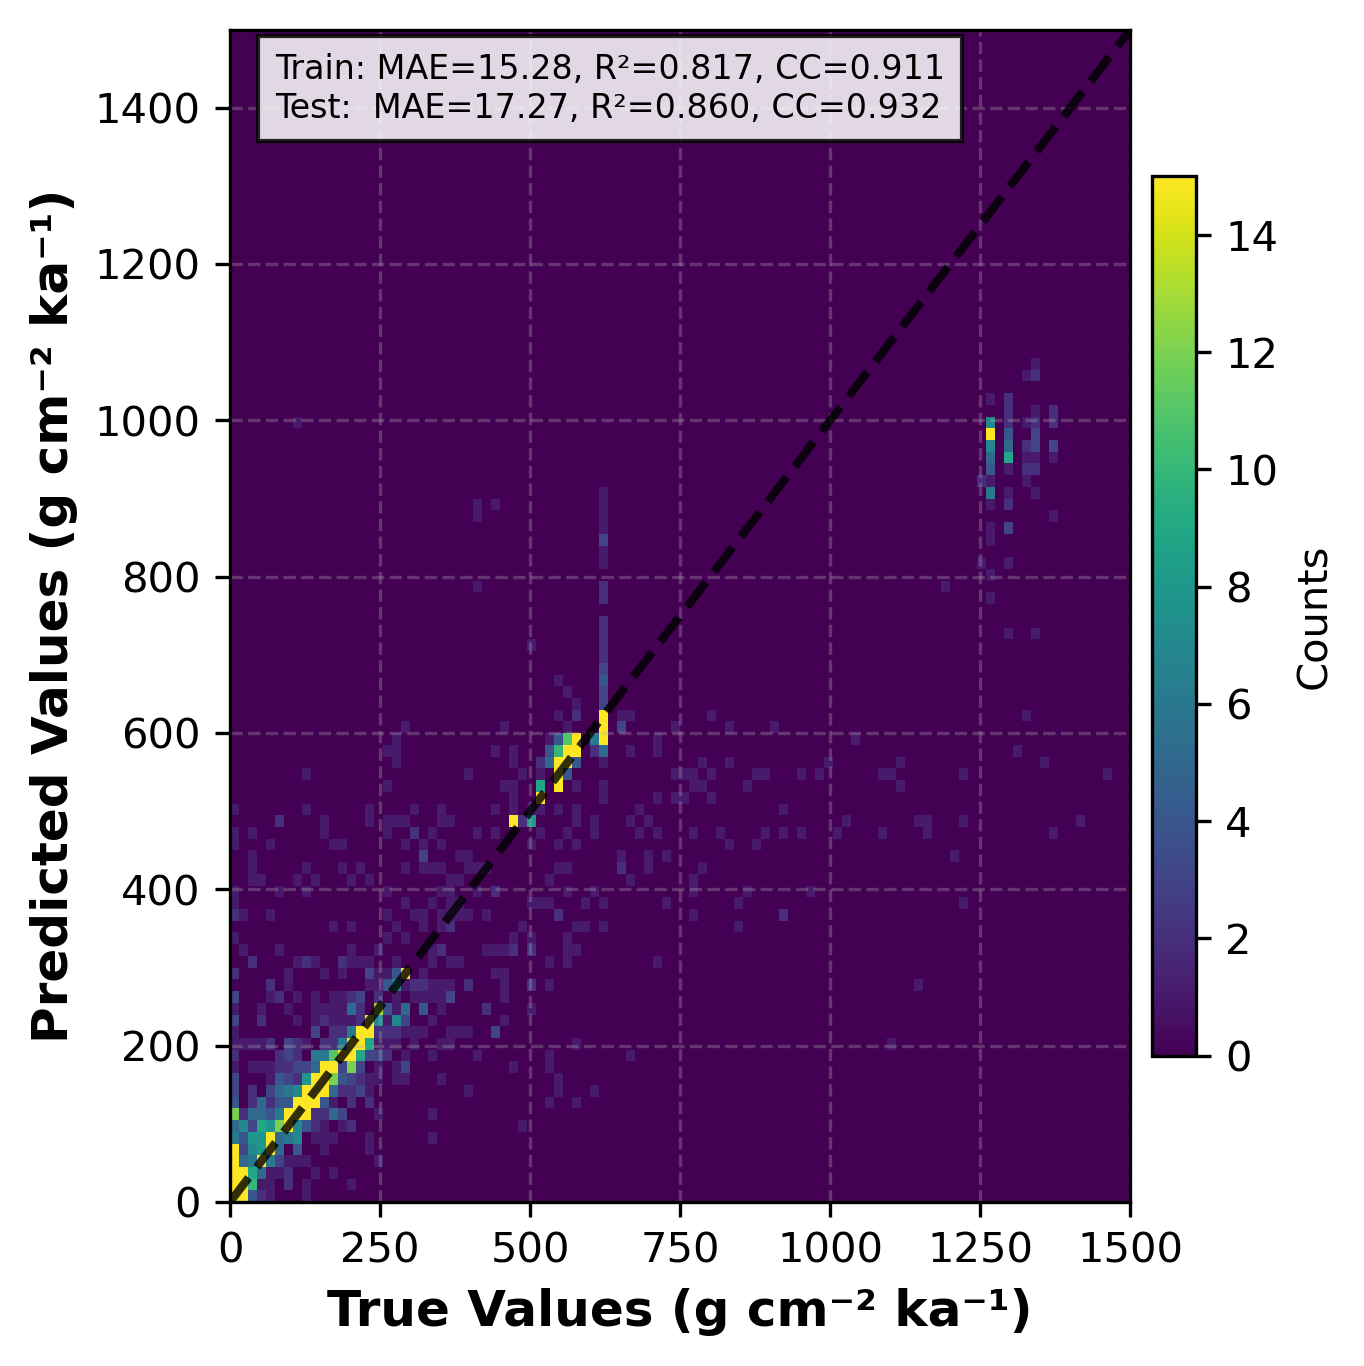

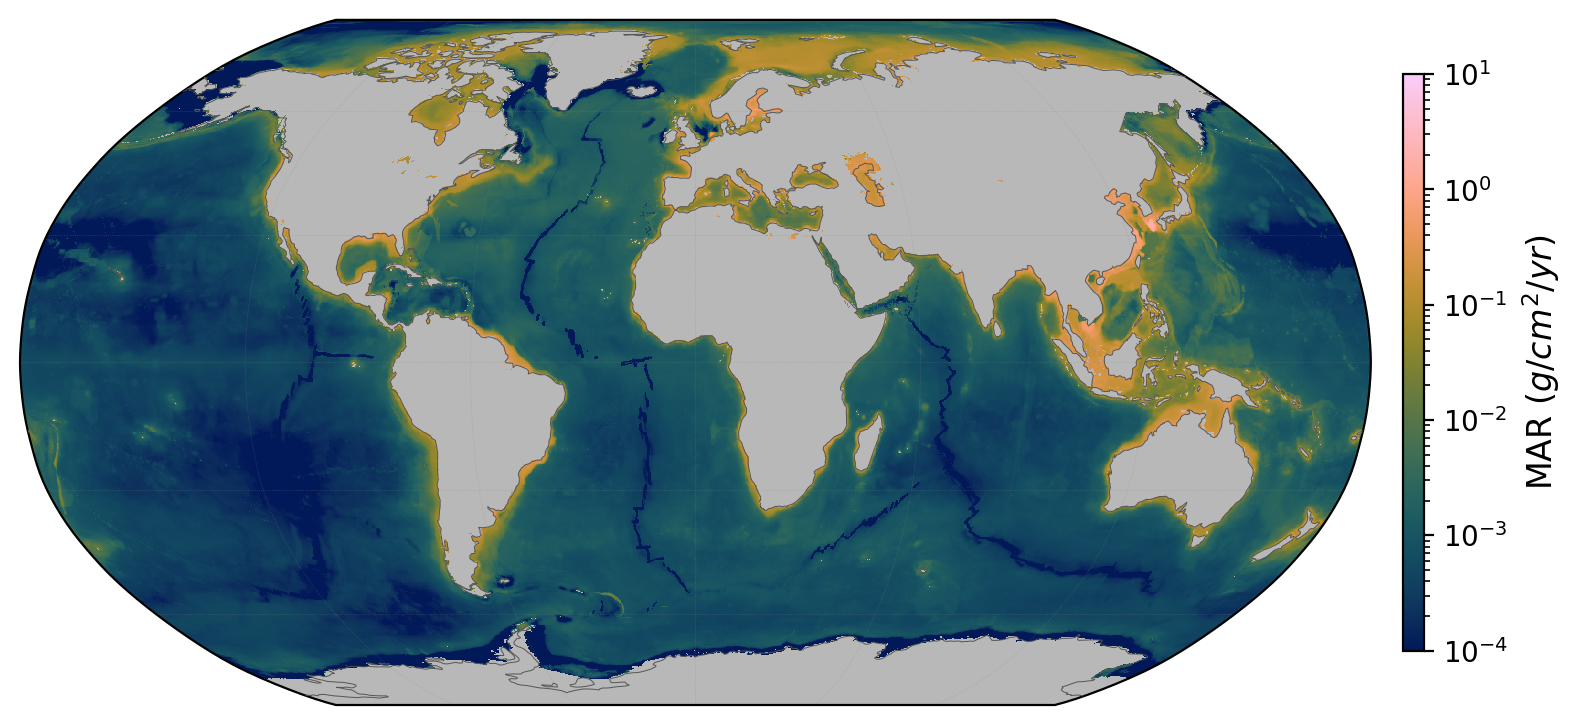

Outputs: data/output/predictionmaps_SedRate/notebooks_tabpfn


In [2]:
from tabpfn import TabPFNRegressor

write_maps = True
out_dir = PREDICTION_MAPS_DIR / "notebooks_tabpfn"
out_dir.mkdir(parents=True, exist_ok=True)

# Fit on training sites, then predict train and test MAR
model = TabPFNRegressor()
model.fit(train_features, train_labels)
train_pred = model.predict(train_features)
test_pred = model.predict(test_features)
tr, te = plot_pred_scatter(train_labels, train_pred, test_labels, test_pred, "TabPFN")
pd.DataFrame([{"model": "tabpfn", **{f"test_{k}": v for k, v in te.items()}}]).to_csv(
    out_dir / "tabpfn_test_summary.csv", index=False
)

if write_maps:
    # Chunked prediction (TabPFN can be memory-heavy; process world files one by one)
    predict_global_map_sklearn(
        model,
        world_dir,
        X_mean,
        X_std,
        DATA_RAW / "island_map.npy",
        out_dir / "prediction_map_MAR_entire_tabpfn_nnimputed.npy",
    )
print("Outputs:", out_dir)
